In [1]:
import sys
from pathlib import Path

# Racine du projet = premier dossier parent contenant src/consolidation
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "consolidation").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from consolidation import config, loaders, quality, preparation, rates
from consolidation.plotting import set_style, PRIMARY, ACCENT, TEXT, TEXT_MUTED

set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
print("Racine du projet :", ROOT.name, "| sources :", config.RAW_DIR.relative_to(ROOT).as_posix())

Racine du projet : repo_wissam | sources : docs


### 1.5 Les indicateurs de pilotage

| Indicateur | Définition | Sens souhaité |
|---|---|---|
| Nombre de livraisons | Nombre de couples × jour livrés (et de camions) sur l'horizon | ↓ |
| Taux de remplissage | Poids (et volume) chargé / capacité, par camion | ↑ |
| Coût de transport | Σ prix des envois (*rate sheet*) | ↓ |
| *Saving* | Coût actuel − coût après consolidation (EUR, %) | ↑ |
| Anticipation moyenne | Nombre moyen de jours d'avance d'un besoin livré (impact stock usine) | à surveiller |
| Lissage | Répartition des livraisons par jour de la semaine et par usine | équilibré |
| Respect des contraintes | Nombre de violations : retard, anticipation > 7 jours, capacité dépassée, quantité non livrée | = 0 |

In [2]:
pd.DataFrame({
    "parametre": ["Capacité camion — poids (kg)", "Capacité camion — volume (m³)", "Anticipation maximale (jours)",
                  "Fréquences autorisées (/ semaine)", "Jours ouvrés", "Jours fériés signalés"],
    "valeur": [config.TRUCK_MAX_WEIGHT_KG, config.TRUCK_MAX_VOLUME_M3, config.MAX_ANTICIPATION_DAYS,
               config.ALLOWED_FREQUENCIES, "lundi → vendredi",
               ", ".join(d.strftime("%d/%m/%Y") for d in sorted(config.PUBLIC_HOLIDAYS))],
}).set_index("parametre")

,valeur
parametre,
Capacité camion — poids (kg),24 500.00
Capacité camion — volume (m³),110.40
Anticipation maximale (jours),7
Fréquences autorisées (/ semaine),"(1, 2, 3, 5)"
Jours ouvrés,lundi → vendredi
Jours fériés signalés,"11/11/2026, 25/12/2026, 01/01/2027"


## 2. Analyse Data Quality

### 2.1 Chargement des trois sources

| Source | Contenu | Rôle |
|---|---|---|
| `released_schedule.csv` | Besoins journaliers par fournisseur, material, usine et quai | **Quoi** livrer, **quand**, **où** |
| `distances.csv` | Distance (km) entre chaque fournisseur et le point de consolidation | **À quelle distance** → ligne de la *rate sheet* |
| `rate_sheet.pdf` | Grille de coût par envoi (distance × poids), marge, surcharge diesel | **Combien ça coûte** |

Le chargement ajoute `line_id`, le numéro de la ligne dans le fichier source. C'est la clé de traçabilité : chaque besoin du dataset final renvoie à sa ligne d'origine.

In [3]:
schedule = loaders.load_schedule()
distances = loaders.load_distances()
rate_sheet = loaders.load_rate_sheet()

pd.DataFrame({
    "source": ["released_schedule.csv", "distances.csv", "rate_sheet.pdf"],
    "lignes": [len(schedule), len(distances), rate_sheet.grid.shape[0]],
    "colonnes": [schedule.shape[1] - 1, distances.shape[1], rate_sheet.grid.shape[1]],
    "remarque": ["+ line_id ajouté", "", "tranches km × tranches kg"],
}).set_index("source")

,lignes,colonnes,remarque
source,,,
released_schedule.csv,5728,10,+ line_id ajouté
distances.csv,156,2,
rate_sheet.pdf,14,15,tranches km × tranches kg


In [4]:
schedule.head()

,line_id,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
0,0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41,2026-11-06,2026-11-08
1,1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08
2,2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41,2026-11-06,2026-11-08
3,3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08
4,4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08


In [5]:
def profile(df):
    return pd.DataFrame({
        "type": df.dtypes.astype(str),
        "valeurs_distinctes": df.nunique(),
        "manquants": df.isna().sum(),
        "min": [df[c].min() if df[c].dtype.kind in "fiMm" else "" for c in df],
        "max": [df[c].max() if df[c].dtype.kind in "fiMm" else "" for c in df],
    })

profile(schedule.drop(columns="line_id"))

,type,valeurs_distinctes,manquants,min,max
date,datetime64[us],35,0,2026-11-09 00:00:00,2027-01-01 00:00:00
supplier_id,string,94,0,,
material,string,1229,0,,
plant,string,4,0,,
unloading_point,string,51,0,,
schedule_quantity,float64,399,0,0.00,100 000.00
weight,float64,1746,169,0.00,58 267.30
volume,float64,60,147,0.01,5.81
transmission_date,datetime64[us],45,0,2026-01-30 00:00:00,2026-11-07 00:00:00
version_date,datetime64[us],1,0,2026-11-08 00:00:00,2026-11-08 00:00:00


In [6]:
needs_raw = schedule[schedule["schedule_quantity"] > 0]
print(f"Horizon : du {schedule['date'].min():%d/%m/%Y} au {schedule['date'].max():%d/%m/%Y} "
      f"({schedule['date'].nunique()} dates distinctes, toutes en jours ouvrés : "
      f"{schedule['date'].dt.day_of_week.lt(5).all()})")
print(f"Version du programme : {schedule['version_date'].unique()[0]:%d/%m/%Y} (unique)")
print(f"Lignes avec besoin (quantité > 0) : {len(needs_raw)} / {len(schedule)}")
print(f"Couples fournisseur × usine : {schedule.groupby(config.COUPLE_KEY).ngroups} "
      f"(dont {needs_raw.groupby(config.COUPLE_KEY).ngroups} avec au moins un besoin)")

needs_raw.groupby("plant").agg(
    lignes=("line_id", "size"), fournisseurs=("supplier_id", "nunique"),
    materials=("material", "nunique"), quais=("unloading_point", "nunique"),
    poids_total_t=("weight", lambda w: w.sum() / 1000),
)

Horizon : du 09/11/2026 au 01/01/2027 (35 dates distinctes, toutes en jours ouvrés : True)
Version du programme : 08/11/2026 (unique)
Lignes avec besoin (quantité > 0) : 4769 / 5728
Couples fournisseur × usine : 185 (dont 181 avec au moins un besoin)


,lignes,fournisseurs,materials,quais,poids_total_t
plant,,,,,
PLT_001,1306,51,364,25,432.86
PLT_002,1419,64,419,7,378.63
PLT_003,449,26,150,7,220.01
PLT_004,1595,40,335,11,962.84


In [7]:
needs_raw[["schedule_quantity", "weight", "volume"]].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
schedule_quantity,4 769.00,1 478.35,4 623.06,1.00,130.00,400.00,1 080.00,5 688.00,18 000.00,100 000.00
weight,4 630.00,430.74,1 526.40,0.77,60.36,146.40,315.50,1 520.99,5 553.10,58 267.30
volume,4 650.00,0.67,0.61,0.01,0.07,0.57,1.14,1.20,2.88,5.81


Les distributions sont très asymétriques. La ligne médiane pèse environ 120 kg, mais quelques lignes dépassent la capacité d'un camion à elles seules.

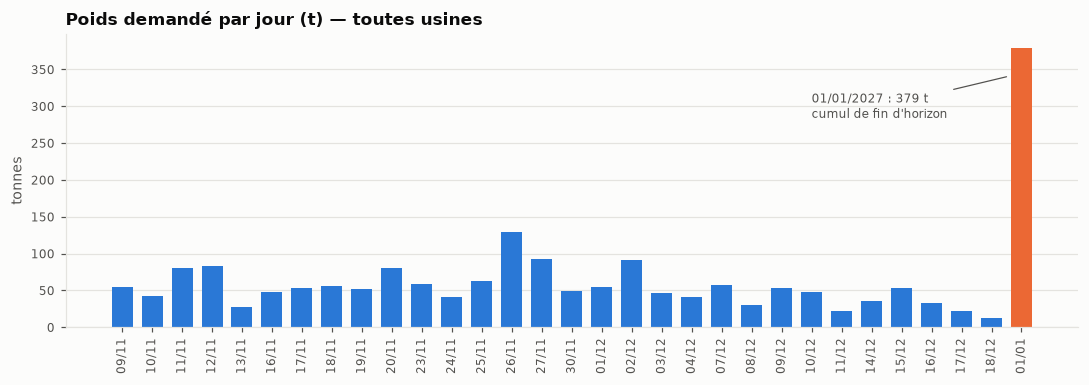

In [8]:
by_day = needs_raw.groupby("date")["weight"].sum() / 1000
last = by_day.index.max()
colors = [ACCENT if d == last else PRIMARY for d in by_day.index]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_day.index.strftime("%d/%m"), by_day.values, color=colors, width=0.7)
ax.set_title("Poids demandé par jour (t) — toutes usines")
ax.set_ylabel("tonnes")
ax.tick_params(axis="x", rotation=90)
ax.annotate(f"01/01/2027 : {by_day[last]:.0f} t\ncumul de fin d'horizon",
            xy=(len(by_day) - 1.4, by_day[last] * 0.9), xytext=(len(by_day) - 8, by_day[last] * 0.75),
            fontsize=8, color=TEXT_MUTED, arrowprops=dict(arrowstyle="-", color=TEXT_MUTED, lw=0.8))
plt.tight_layout(); plt.show()

**On retire le 01/01/2027 de la consolidation.** Ce n'est pas un vrai jour de besoin : c'est la dernière date du programme, sur laquelle sont cumulées toutes les commandes prévues au-delà de l'horizon. Il pèse environ 7 fois un jour normal et tombe un jour férié, juste après les jours vides des fêtes. Le consolider fausserait les profils de livraison et les économies calculées.

**Distribution des besoins courants.** Pour lire la distribution des besoins réels, on enlève du tableau ci-dessous les lignes du 01/01 et les lignes dont le poids dépasse à lui seul la capacité d'un camion (24,5 t) : ces valeurs extrêmes écraseraient les statistiques.

In [9]:
truck_heavy = needs_raw["weight"] > config.TRUCK_MAX_WEIGHT_KG
courants = needs_raw[(needs_raw["date"] != last) & ~truck_heavy]
print(f"Lignes retirées : {(needs_raw['date'] == last).sum()} du 01/01 et "
      f"{((needs_raw['date'] != last) & truck_heavy).sum()} de plus de 24,5 t → {len(courants)} lignes restantes")
courants[["schedule_quantity", "weight", "volume"]].describe(percentiles=[.25, .5, .75, .95, .99]).T

Lignes retirées : 379 du 01/01 et 1 de plus de 24,5 t → 4389 lignes restantes


,count,mean,std,min,25%,50%,75%,95%,99%,max
schedule_quantity,4 389.00,1 351.81,3 821.37,1.00,132.00,400.00,1 000.00,5 000.00,16 000.00,100 000.00
weight,4 255.00,373.32,1 054.98,0.77,51.68,139.00,287.00,1 326.44,5 139.91,21 826.80
volume,4 273.00,0.66,0.60,0.01,0.07,0.57,1.14,1.20,2.88,5.81


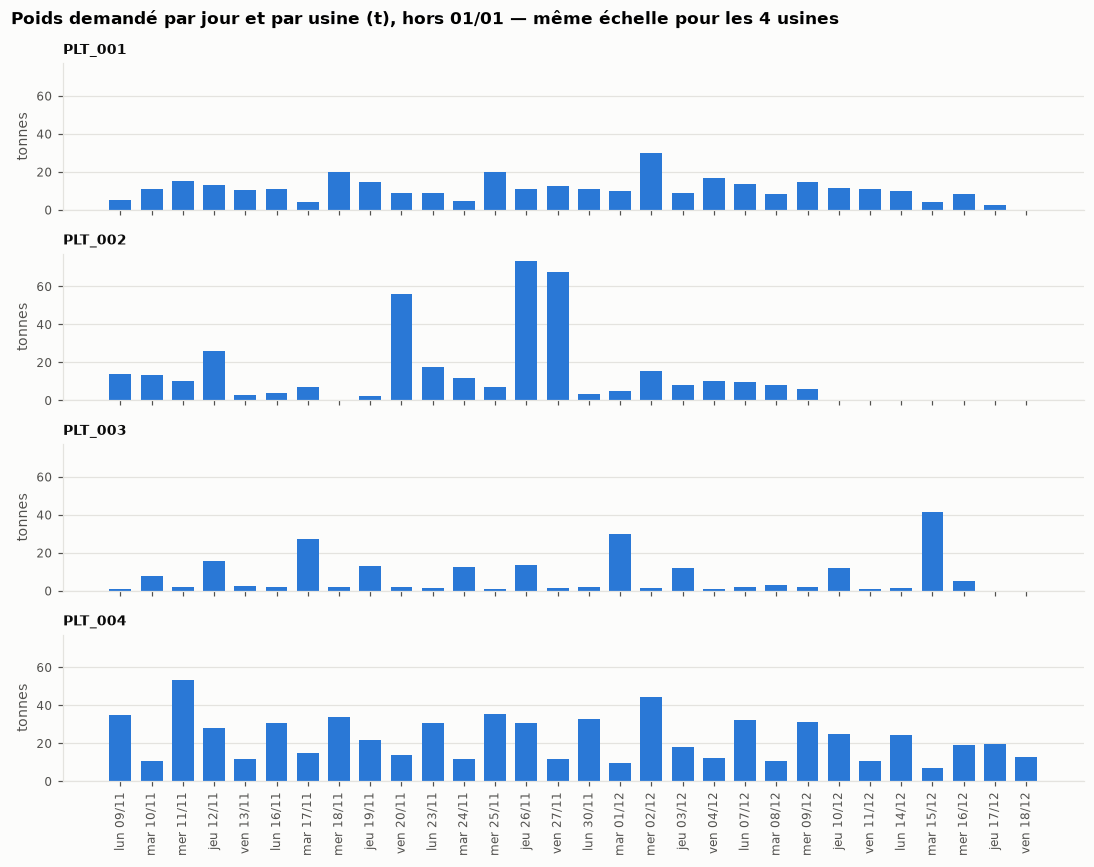

Jours avec au moins un besoin, sur 30 : {'PLT_001': 29, 'PLT_002': 23, 'PLT_003': 28, 'PLT_004': 30}


In [10]:
plants = sorted(needs_raw["plant"].unique())
per_plant = (needs_raw[needs_raw["date"] != last]
             .pivot_table(index="date", columns="plant", values="weight", aggfunc="sum")
             .reindex(columns=plants).fillna(0) / 1000)
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
labels = [f"{jours[d.weekday()]} {d:%d/%m}" for d in per_plant.index]

fig, axes = plt.subplots(len(plants), 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, plant in zip(axes, plants):
    ax.bar(labels, per_plant[plant].values, color=PRIMARY, width=0.7)
    ax.set_title(plant, fontsize=9)
    ax.set_ylabel("tonnes")
axes[-1].tick_params(axis="x", rotation=90)
fig.suptitle("Poids demandé par jour et par usine (t), hors 01/01 — même échelle pour les 4 usines",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
print("Jours avec au moins un besoin, sur", len(per_plant), ":", (per_plant > 0).sum().to_dict())

Chaque usine a son propre rythme :

- **PLT_004**, la plus chargée, a un besoin tous les jours, avec des pics le lundi et le mercredi (souvent plus de 30 t, jusqu'à 53 t le 11/11) et des creux le mardi et le vendredi (environ 10 à 15 t).
- **PLT_003** concentre ses besoins le mardi et le jeudi, avec un très gros mardi une semaine sur deux (27 t le 17/11, 30 t le 01/12, 41 t le 15/12).
- **PLT_002** est irrégulière : trois très gros jours (56 t le 20/11, 74 t le 26/11, 67 t le 27/11), puis plus aucun besoin à partir du 10/12.
- **PLT_001** a une charge régulière, presque tous les jours.

**Conséquence :** le lissage doit se faire **usine par usine**, en évitant d'ajouter des livraisons les jours déjà chargés (par exemple le lundi et le mercredi pour PLT_004).

### 2.3 `distances.csv`

In [11]:
sched_sup = schedule["supplier_id"].unique()
d_sched = distances[distances["supplier_id"].isin(sched_sup)]
print(f"{len(distances)} fournisseurs référencés, dont {len(d_sched)} présents dans le planning")
print(f"Distances manquantes : {distances['distance'].isna().sum()} au total, "
      f"dont {d_sched['distance'].isna().sum()} pour des fournisseurs du planning : "
      f"{', '.join(d_sched.loc[d_sched['distance'].isna(), 'supplier_id'])}")
print(f"Fournisseurs du planning absents du fichier : {len(set(sched_sup) - set(distances['supplier_id']))}")
d_sched["distance"].describe().to_frame("distance (km), fournisseurs du planning").T

156 fournisseurs référencés, dont 94 présents dans le planning
Distances manquantes : 11 au total, dont 2 pour des fournisseurs du planning : SUP_00047, SUP_00130
Fournisseurs du planning absents du fichier : 0


,count,mean,std,min,25%,50%,75%,max
"distance (km), fournisseurs du planning",92.00,62.91,35.50,6.00,33.00,60.50,82.25,149.00


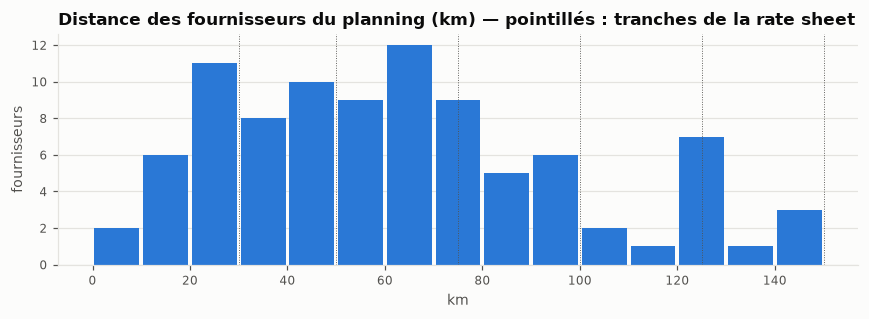

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(d_sched["distance"].dropna(), bins=range(0, 160, 10), color=PRIMARY, rwidth=0.92)
for b in [30, 50, 75, 100, 125, 150]:
    ax.axvline(b, color=TEXT_MUTED, lw=0.6, ls=":")
ax.set_title("Distance des fournisseurs du planning (km) — pointillés : tranches de la rate sheet")
ax.set_xlabel("km"); ax.set_ylabel("fournisseurs")
plt.tight_layout(); plt.show()

Tous les fournisseurs du planning sont à moins de 150 km : seules les 6 premières tranches de distance de la *rate sheet* serviront.

### 2.4 `rate_sheet.pdf` — la grille tarifaire

Le PDF est lu automatiquement (`loaders.load_rate_sheet`), et non recopié à la main. La grille est ensuite validée en recalculant l'exemple fourni dans le document.

In [13]:
grid = rate_sheet.grid.copy()
grid.index = [f"≤ {k:g}" if np.isfinite(k) else "> 650" for k in grid.index]
grid.columns = [f"≤ {k:g}" if np.isfinite(k) else "> 4000" for k in grid.columns]
grid.index.name, grid.columns.name = "km \\ kg", None
grid

,≤ 50,≤ 100,≤ 200,≤ 300,≤ 400,≤ 500,≤ 750,≤ 1000,≤ 1500,≤ 2000,≤ 2500,≤ 3000,≤ 3500,≤ 4000,> 4000
km \ kg,,,,,,,,,,,,,,,
≤ 30,4.75,6.66,8.56,10.73,13.06,14.75,17.75,22.35,25.67,31.40,35.08,35.16,37.73,40.87,42.42
≤ 50,5.78,7.94,10.74,13.07,15.45,17.35,20.96,25.32,30.05,35.97,40.52,42.90,47.04,51.05,52.80
≤ 75,6.92,9.54,13.14,15.99,18.43,20.59,24.96,29.02,35.52,41.70,47.33,52.58,57.55,62.30,64.28
≤ 100,7.33,10.27,14.35,17.61,20.40,22.88,27.96,32.63,40.20,47.30,53.77,59.79,65.47,70.89,73.04
≤ 125,7.77,10.99,15.57,19.24,22.37,25.17,30.95,36.25,44.89,52.91,60.21,66.99,73.38,79.47,81.80
≤ 150,8.26,11.83,17.04,21.23,24.84,28.09,34.86,41.01,51.20,60.59,69.12,77.06,84.54,91.65,94.22
≤ 175,9.85,14.04,19.96,24.65,28.69,32.28,39.74,46.45,57.51,68.25,78.04,87.13,95.69,103.83,106.65
≤ 200,11.45,16.31,23.21,28.67,33.33,37.49,46.16,53.90,66.69,78.23,88.63,98.88,108.54,117.72,120.80
≤ 250,13.56,19.66,28.43,35.44,41.45,46.84,58.22,68.33,85.24,100.38,114.05,126.66,138.46,149.64,153.36


### 2.5 DICTIONNAIRE / CARTOGRAPHIE (ARIANNE)


#### Où se situent les livraisons actuelles dans la grille tarifaire ?

On croise les trois sources : chaque livraison actuelle (couple × jour) est placée dans la grille selon la distance de son fournisseur et son poids.

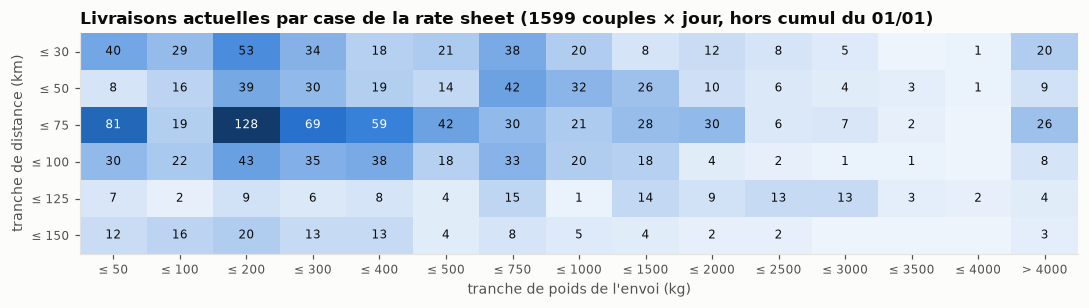

Livraisons ≤ 1 000 kg : 80%   |   > 4 000 kg : 4%


In [14]:
from matplotlib.colors import LinearSegmentedColormap

cur = (needs_raw.merge(distances, on="supplier_id", how="left")
       .groupby(config.COUPLE_KEY + ["date"]).agg(weight=("weight", "sum"), distance=("distance", "first"))
       .reset_index())
cur = cur[(cur["date"] != last) & cur["distance"].notna() & (cur["weight"] > 0)]
cur["km"] = rates.brackets(rate_sheet.grid.index, cur["distance"])
cur["kg"] = rates.brackets(rate_sheet.grid.columns, cur["weight"])
mat = pd.crosstab(cur["km"], cur["kg"]).reindex(columns=rate_sheet.grid.columns, fill_value=0)

cmap = LinearSegmentedColormap.from_list("seq", ["#eef4fc", PRIMARY, "#123a6b"])
fig, ax = plt.subplots(figsize=(10, 2.9))
ax.imshow(mat.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(mat.shape[1]), [f"≤ {c:g}" if np.isfinite(c) else "> 4000" for c in mat.columns])
ax.set_yticks(range(mat.shape[0]), [f"≤ {k:g}" for k in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8,
                    color="white" if v > mat.values.max() * 0.45 else TEXT)
ax.grid(False)
ax.set_xlabel("tranche de poids de l'envoi (kg)"); ax.set_ylabel("tranche de distance (km)")
ax.set_title(f"Livraisons actuelles par case de la rate sheet ({len(cur)} couples × jour, hors cumul du 01/01)")
plt.tight_layout(); plt.show()

print(f"Livraisons ≤ 1 000 kg : {(cur['weight'] <= 1000).mean():.0%}   |   > 4 000 kg : {(cur['weight'] > 4000).mean():.0%}")

### 2.6 Valeurs manquantes ou nulles

**Règle :** sur une ligne avec besoin, un poids ou un volume **à 0 est traité exactement comme une valeur manquante**. Les deux ont le même impact : on ne connaît pas la charge réelle de la ligne. Ils sont donc comptés ensemble (`quality.is_missing`) et complétés par la même règle (section 3).

In [15]:
pd.concat({
    "schedule (quantité > 0)": quality.missing_values(needs_raw),
    "distances": quality.missing_values(distances),
})

vides  nuls  manquants_ou_nuls  pct
schedule (quantité > 0) weight      139     0                139 2.91
                        volume      119     0                119 2.50
distances               distance     11     0                 11 7.05

In [16]:
w_miss, v_miss = quality.is_missing(needs_raw["weight"]), quality.is_missing(needs_raw["volume"])
miss = needs_raw[w_miss | v_miss]
print(f"{len(miss)} lignes avec besoin ont un poids ou un volume manquant ou nul ; "
      f"{(w_miss & v_miss).sum()} n'ont ni l'un ni l'autre.")
has_weight_elsewhere = miss["material"].isin(needs_raw.loc[~w_miss, "material"])
print(f"Seules {has_weight_elsewhere[w_miss[miss.index]].sum()} lignes à poids manquant ou nul concernent un material "
      f"dont le poids est connu ailleurs dans le planning → un repli au-delà du material est nécessaire.")
miss.groupby(config.COUPLE_KEY).size().sort_values(ascending=False).head(8).rename("lignes incomplètes").to_frame()

139 lignes avec besoin ont un poids ou un volume manquant ou nul ; 119 n'ont ni l'un ni l'autre.
Seules 21 lignes à poids manquant ou nul concernent un material dont le poids est connu ailleurs dans le planning → un repli au-delà du material est nécessaire.


lignes incomplètes
supplier_id plant                      
SUP_00129   PLT_003                  24
            PLT_001                  19
SUP_00001   PLT_004                  17
SUP_00117   PLT_002                  12
SUP_00153   PLT_004                  11
SUP_00046   PLT_002                   6
SUP_00107   PLT_002                   5
SUP_00145   PLT_002                   5

Les valeurs manquantes sont **concentrées sur quelques couples** : SUP_00129 en représente à lui seul près d'un tiers (43 lignes sur 139). Il ne s'agit donc pas d'un bruit aléatoire mais de *materials* dont la fiche logistique n'est pas renseignée. C'est un point à remonter au métier.